# tool과 Ch 4 함수 재사용

**이 노트북에서 할 일**

1. Ch 4에서 배운 주문 조회 함수 `fetch_orders`를 도구 파일에서 가져와 그대로 부릅니다.
2. 함수 위에 `@tool` 줄을 붙여 도구로 감싸고, 도구 이름·설명·입력 형식이 어디서 오는지 봅니다.
3. 도구를 Ch 4 함수처럼 괄호로 부르면 멈추는 것을 봅니다(Before).
4. 도구를 인자 딕셔너리와 함께 `.invoke`로 불러, 함수를 직접 부른 결과와 견줍니다(After).

**준비물** — 이 절은 모델을 부르지 않습니다.
모델 요청은 0번이라 API 키가 필요 없고, 드는 비용도 없습니다.
도구를 만들고 부르는 일은 모두 파이썬 안에서 끝나기 때문입니다.
모델에게 도구를 알려 주는 일은 04절부터 합니다.

읽는 파일은 실습 폴더의 `data/orders.csv` 하나이고, 새로 쓰는 파일은 없습니다.
Ch 4 함수는 같은 폴더의 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 3초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
langchain 1.4.0, langchain-core 1.6.2, pandas 3.0.5입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
Ch 4 함수를 도구로 감싸고, 도구의 이름·설명·입력 형식을 보는 자리입니다.
5~7절은 도구를 잘못 불러 보고, 고쳐 부르고, 값을 바꿔 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 파란 상자 셋 함수 이름 list_orders_by_status, 독스트링 한 줄, 매개변수 status str이 가운데 회색 상자 @tool 줄이 감쌈 도구 객체 StructuredTool로 모이고, 거기서 아래 노란 상자 셋 도구 이름 list_orders_by_status, 도구 설명 독스트링과 같은가 True, 입력 형식 status type string으로 나뉘며, 맨 아래 초록 상자에 CSV 파일 위치 csv_path는 몸통 안에서만 읽어 세 칸 어디에도 없다고 적힌 그림](attachment:01-1-함수에서-도구로.png)

위에서 아래로 읽습니다. 맨 위 파란 상자 셋이 우리가 적은 함수의 세 부분입니다.
가운데 회색 상자는 LangChain의 `@tool` 줄이 만든 도구 객체입니다.
아래 노란 상자 셋이 도구에 붙은 이름·설명·입력 형식이고, 맨 아래 초록 CSV 파일 위치는 그 세 칸에 없습니다.
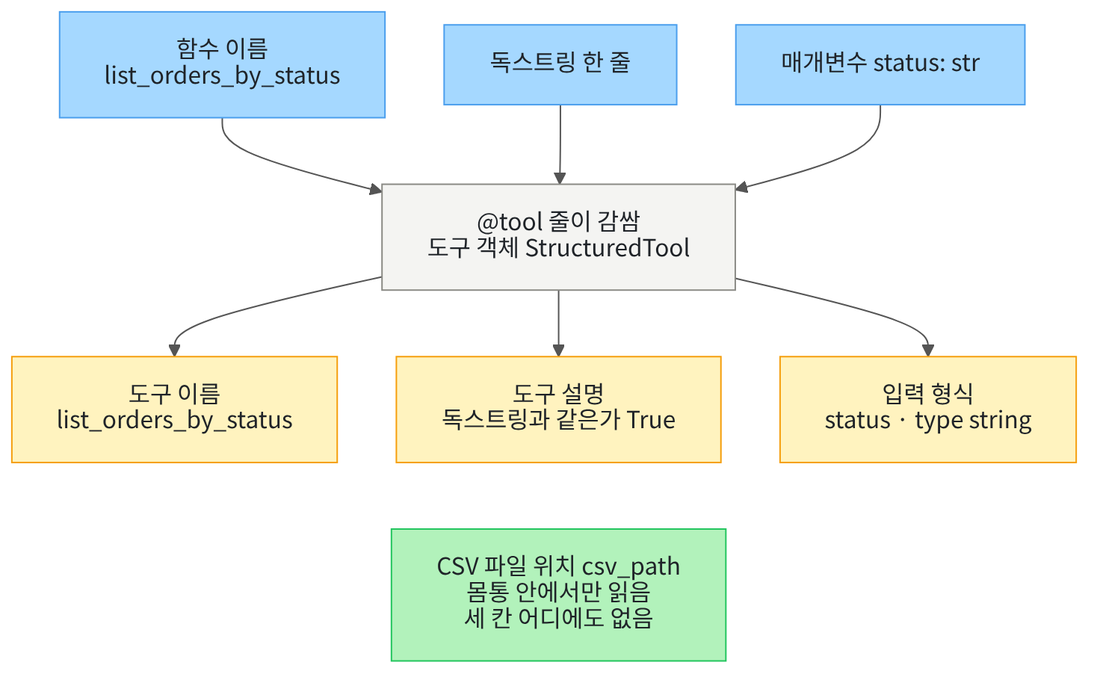

## 1. 준비

이 절은 Ch 4의 주문 조회 함수를 모델이 고를 수 있는 도구로 감쌉니다.
제목의 tool은 도구라는 뜻이고, 이 교재는 「도구」라고 부릅니다.

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "pandas==3.0.5"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("pandas:", version("pandas"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
pandas: 3.0.5


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`pandas: 3.0.5`가 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

Ch 2 07절에서 임시 폴더에 만든 같은 이름의 모듈과는 다른 파일입니다.
가져오기가 현재 작업 폴더에서 파일을 찾는 것은 그 절에서 본 그대로입니다.

다음 셀은 이 절에서 쓸 이름 넷을 가져옵니다.
함수 `tool`은 함수를 도구로 감쌀 때 쓰는 LangChain 이름입니다.
함수 `convert_to_openai_tool`은 4절에서 도구 명세를 볼 때 씁니다.
모듈 `os`는 그다음 준비 셀에서 CSV 파일 위치를 찾을 때 씁니다.

In [2]:
# CSV 파일 위치를 찾을 os, 도구를 만드는 tool, 도구 명세를 만드는 함수, Ch 4 함수를 가져옵니다
import os

from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

from order_tools import fetch_orders

print("가져온 이름:", "os", "tool", "convert_to_openai_tool", "fetch_orders")

가져온 이름: os tool convert_to_openai_tool fetch_orders


**결과 읽기** — 출력 줄 `가져온 이름: os tool convert_to_openai_tool fetch_orders`로 이름 넷을 가져왔습니다.
함수 `fetch_orders`는 Ch 4 실습 폴더 `data_tools.py`에 있던 판을 이 챕터 도구 파일로 옮긴 것입니다.
옮기면서 자료형 표시와 설명 글을 빼고 주석을 달았습니다.

다음 셀은 주문 CSV 파일이 있는 프로젝트 맨 위 폴더를 찾습니다.
노트북은 보통 `notebooks/` 폴더에서 열리지만, 실행 도구가 다른 자리에서 시작할 수도 있습니다.
그래서 후보 세 곳을 차례로 보고, 파일이 있는 첫 자리에서 `break`로 멈춥니다.
함수 `os.path.exists`는 그 자리에 파일이 있으면 `True`를 내놓습니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.

변수 `csv_path`에 CSV 파일 위치를 담았습니다.
이 위치는 모델이 고를 값이 아니라 노트북이 정해 두는 값입니다.

## 2. Ch 4 함수 다시 부르기

Ch 4 01절은 주문 CSV를 읽어 한 상태의 주문만 딕셔너리 목록으로 내놓는 함수를 만들었습니다.
그 절의 노트북 판은 파일 이름과 상태를 위치 인자로 받았습니다.
Ch 4 실습 폴더 판은 CSV 파일 위치를 먼저 받고, 상태는 키워드 인자 `status=`로 받습니다.
이 챕터는 Ch 4 01절이 약속한 대로 실습 폴더 판을 씁니다.

함수 머리의 별표 `*`는 그 뒤 인자를 이름을 붙여서만 넘기게 하는 표시입니다.
인자 `status=None`은 상태를 넘기지 않으면 `None`이 들어간다는 표시입니다.
그때 함수는 모든 줄을 남깁니다.
다음 셀은 상태를 고르지 않고 CSV 파일 위치만 넣어 부릅니다.

In [4]:
# Ch 4 함수에 CSV 파일 위치만 넣어, 상태를 고르지 않은 주문 전체를 읽습니다
all_rows = fetch_orders(csv_path)
print("주문 수:", len(all_rows))
print("주문 목록:")
for row in all_rows:
    print(row)

주문 수: 4
주문 목록:
{'order_id': 'O101', 'customer_id': 'C001', 'status': 'paid', 'amount': 32000}
{'order_id': 'O102', 'customer_id': 'C002', 'status': 'pending', 'amount': 18000}
{'order_id': 'O103', 'customer_id': 'C001', 'status': 'paid', 'amount': 27000}
{'order_id': 'O104', 'customer_id': 'C003', 'status': 'cancelled', 'amount': 9000}


**결과 읽기** — 출력 줄 `주문 수: 4`로 주문 네 줄을 읽었습니다.
라벨 줄 `주문 목록:` 아래 네 줄이 주문 하나씩입니다.
줄마다 칸 넷이 든 딕셔너리이고, 주문 번호는 `O101`부터 `O104`까지입니다.

다음 셀은 첫 줄의 칸 이름과 칸마다 값의 자료형을 봅니다.
Ch 4 01절에서 자료형을 먼저 확인하던 습관을 이어 갑니다.

In [5]:
# 첫 주문 한 줄의 칸 이름과, 칸마다 값의 자료형을 봅니다
first_row = all_rows[0]
row_keys = list(first_row.keys())
print("칸 이름:", row_keys)
for key in first_row:
    print(key, "|", type(first_row[key]).__name__)

칸 이름: ['order_id', 'customer_id', 'status', 'amount']
order_id | str
customer_id | str
status | str
amount | int


**결과 읽기** — 출력 줄 `칸 이름: ['order_id', 'customer_id', 'status', 'amount']`가 네 칸입니다.
아래 네 줄에서 칸 `amount`만 `int`이고, 나머지 셋은 `str`입니다.

함수는 `dtype`에 딕셔너리를 넣어 주문 번호와 고객 번호 두 칸만 글자로 읽습니다.
Ch 4 01절이 말만 하고 실행하지 않았던 방법입니다(글자로 둘 칸만 따로 정하기).
금액 칸은 정수로 남습니다.
다만 이 CSV의 번호에는 글자 O·C가 섞여 있어, `dtype` 없이 읽어도 같은 자료형이 나옵니다.
차이는 Ch 4 01절이 예로 든 01234처럼 앞자리 0이 있는 번호에서 납니다.

다음 셀은 키워드 인자 `status="paid"`로 결제된 주문만 읽습니다.

In [6]:
# 키워드 인자 status=로 상태를 골라 결제된(paid) 주문만 읽습니다(Ch 4 함수를 직접 부름)
paid_rows = fetch_orders(csv_path, status="paid")
print("결제된 주문 수:", len(paid_rows))
for row in paid_rows:
    print(row["order_id"], "|", row["status"], "|", row["amount"])

결제된 주문 수: 2
O101 | paid | 32000
O103 | paid | 27000


**결과 읽기** — 출력 줄 `결제된 주문 수: 2` 아래에 `O101 | paid | 32000`과 `O103 | paid | 27000`이 보입니다.
이 결과는 6절에서 도구로 부른 결과와 견줍니다.

## 3. 함수를 도구로 감싸기

도구(tool)는 모델이 필요할 때 고를 수 있게 이름·설명·입력 형식을 붙여 감싼 함수입니다.
식당으로 치면 주방의 요리를 메뉴판에 한 줄로 올리는 일과 같습니다.
이 절에서는 Ch 4 함수를 부르는 작은 함수를 만들고, 그 함수를 도구로 감쌉니다.

함수 위의 `@tool` 줄은 데코레이터 줄입니다.
데코레이터 줄은 함수 위에 붙여 그 함수를 다른 것으로 감싸는 표시입니다.
요리법 카드에 「메뉴판에 올림」 표를 붙이는 일과 비슷합니다.
다음 셀에서는 `@tool` 줄이 아래 함수를 도구로 등록합니다.

파이썬은 함수를 만든 뒤 곧바로 `tool`에 넣고, `tool`이 만든 도구를 같은 이름에 담습니다.
Ch 2 09절의 `@` 줄과 같은 규칙입니다.
Ch 2에서 건너뛸 수 있는 절이라, 배우지 않았다면 함께 읽어 보세요.

독스트링(docstring)은 함수 첫 줄에 큰따옴표 세 개로 감싸 적는 설명 글입니다.
요리법 카드 맨 위에 적는 한 줄 소개와 같습니다.
도구로 감싸면 이 글이 도구 설명이 됩니다.

매개변수 `status: str`의 `: str`은 Ch 2 07절에서 배운 타입힌트입니다.
Ch 2 07절에서는 타입힌트가 값을 검사하지 않는다고 배웠습니다.
도구에서는 이 표시가 입력 형식의 자료형으로 들어갑니다.
이 챕터는 타입힌트를 도구로 감쌀 함수의 매개변수에만 적습니다.

몸통은 Ch 4 함수를 부르는 한 줄입니다.
CSV 파일 위치는 인자로 받지 않고 1절에서 정한 `csv_path`를 씁니다.
파일 위치는 모델이 고를 값이 아니기 때문입니다.
손님이 메뉴를 고를 때 주방 창고 위치까지 고르지 않는 것과 같습니다.

In [7]:
# Ch 4 함수를 부르는 작은 함수를 도구로 감쌉니다(CSV 파일 위치는 노트북이 정하고, 상태만 인자로 받습니다)
@tool
def list_orders_by_status(status: str):
    """주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다."""
    # 몸통은 Ch 4 함수를 한 번 부르는 한 줄입니다
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `list_orders_by_status`는 상태 글 하나를 받아 그 상태의 주문 목록을 내놓습니다.

다음 셀은 `@tool` 줄을 지난 뒤 두 이름에 무엇이 담겼는지 종류를 봅니다.

In [8]:
# @tool 줄을 지난 뒤 두 이름에 무엇이 담겼는지 종류를 봅니다
print("fetch_orders의 종류:", type(fetch_orders).__name__)
print("list_orders_by_status의 종류:", type(list_orders_by_status).__name__)

fetch_orders의 종류: function
list_orders_by_status의 종류: StructuredTool


**결과 읽기** — 출력 줄 `fetch_orders의 종류: function`은 도구 파일에서 가져온 평범한 함수입니다.
출력 줄 `list_orders_by_status의 종류: StructuredTool`은 이 이름이 함수가 아니라 도구를 가리킨다는 뜻입니다.
이름 `StructuredTool`은 LangChain이 입력 형식이 있는 도구에 붙이는 종류 이름입니다.
앞 셀에서 `def`로 함수를 만들었지만, `@tool` 줄이 같은 이름에 도구를 담았습니다.

다음 셀은 도구 안에 감싸 둔 원래 함수를 꺼내 봅니다.
원래 함수는 도구 객체의 속성 `func`에 들어 있습니다.

In [9]:
# 도구 안에 감싸 둔 원래 함수를 속성 func로 꺼내 종류와 이름을 봅니다
inner_function = list_orders_by_status.func
print("func의 종류:", type(inner_function).__name__)
print("func의 이름:", inner_function.__name__)

func의 종류: function
func의 이름: list_orders_by_status


**결과 읽기** — 출력 줄 `func의 종류: function`과 `func의 이름: list_orders_by_status`가 보입니다.
원래 함수가 도구 안에 들어 있습니다.
도구로 감싼 일은 함수를 고친 것이 아니라 바깥에서 감싼 것입니다.

## 4. 도구 이름·설명·입력 형식

도구에는 모델이 읽을 칸 셋이 붙습니다.
도구 이름(name), 도구 설명(description), 입력 형식(args)입니다.
다음 셀은 앞의 둘을 출력하고, 도구 설명이 독스트링과 같은지 봅니다.

In [10]:
# 도구 이름은 함수 이름에서, 도구 설명은 독스트링에서 옵니다
print("도구 이름:", list_orders_by_status.name)
print("도구 설명:", list_orders_by_status.description)
# 함수의 속성 __doc__에는 독스트링이 들어 있습니다
print("독스트링과 같은가:", list_orders_by_status.description == inner_function.__doc__)

도구 이름: list_orders_by_status
도구 설명: 주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다.
독스트링과 같은가: True


**결과 읽기** — 출력 줄 `도구 이름: list_orders_by_status`는 함수 이름과 같습니다.
출력 줄 `도구 설명:` 뒤 글은 3절에서 적은 독스트링입니다.
출력 줄 `독스트링과 같은가: True`로 두 글이 같습니다.
설명 글에 적은 상태 셋(paid, pending, cancelled)은 모델이 읽을 안내입니다.

다음 셀은 입력 형식을 봅니다.
입력 형식(스키마, schema)은 도구가 받는 인자의 이름과 자료형을 적은 틀입니다.
메뉴판의 「맵기 선택」 칸처럼, 주문할 때 채울 칸을 알려 줍니다.
도구 객체의 속성 `args`에 딕셔너리로 들어 있습니다.

In [11]:
# 입력 형식(args)은 매개변수 이름과 타입힌트에서 옵니다
print("입력 형식:", list_orders_by_status.args)
arg_names = list(list_orders_by_status.args.keys())
print("모델이 채울 인자:", arg_names)

입력 형식: {'status': {'title': 'Status', 'type': 'string'}}
모델이 채울 인자: ['status']


**결과 읽기** — 출력 줄 `입력 형식: {'status': {'title': 'Status', 'type': 'string'}}`에서 인자는 `status` 하나입니다.
칸 `type`의 값 `string`은 글이라는 뜻이고, 타입힌트 `str`에서 왔습니다.
칸 `title`은 인자 이름의 첫 글자를 대문자로 바꿔 만든 제목입니다.
출력 줄 `모델이 채울 인자: ['status']`에 CSV 파일 위치는 없습니다.

다음 셀은 이 도구를 모델 요청에 실을 모양으로 바꿔 봅니다.
도구 명세(tool definition)는 도구 이름·설명·입력 형식을 한 딕셔너리에 모은 것입니다.
메뉴판에 올라간 한 줄 전체와 같습니다.
함수 `convert_to_openai_tool`은 도구를 받아 OpenAI 모델이 읽는 모양의 도구 명세를 내놓습니다.
이 셀은 모델을 부르지 않고 모양만 만듭니다.

In [12]:
# 도구를 모델 요청에 실을 모양(도구 명세)으로 바꿔 봅니다(모델 요청 없음)
tool_spec = convert_to_openai_tool(list_orders_by_status)
print("도구 명세:")
print(tool_spec)

도구 명세:
{'type': 'function', 'function': {'name': 'list_orders_by_status', 'description': '주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다.', 'parameters': {'properties': {'status': {'type': 'string'}}, 'required': ['status'], 'type': 'object'}}}


**결과 읽기** — 라벨 줄 `도구 명세:` 아래 한 줄이 도구 명세입니다.
맨 바깥 칸 `type`의 값은 `function`이고, 칸 `function` 안에 이름·설명·입력 형식이 들어 있습니다.

다음 셀은 명세의 칸을 하나씩 꺼내 봅니다.
마지막 줄은 명세 전체를 글로 바꿔 `csv`라는 글자가 들어 있는지 봅니다.

In [13]:
# 도구 명세에서 이름·설명·입력 형식이 들어간 칸을 꺼내고, CSV 파일 위치가 있는지 봅니다
function_part = tool_spec["function"]
part_keys = list(function_part.keys())
print("명세의 칸:", part_keys)
print("명세의 인자:", function_part["parameters"]["properties"])
print("꼭 채울 인자:", function_part["parameters"]["required"])
print("명세에 csv 글자가 있는가:", "csv" in str(tool_spec))

명세의 칸: ['name', 'description', 'parameters']
명세의 인자: {'status': {'type': 'string'}}
꼭 채울 인자: ['status']
명세에 csv 글자가 있는가: False


**결과 읽기** — 출력 줄 `명세의 칸: ['name', 'description', 'parameters']`가 도구 이름·설명·입력 형식 자리입니다.
출력 줄 `명세의 인자: {'status': {'type': 'string'}}`와 `꼭 채울 인자: ['status']`로 채울 인자는 상태 하나입니다.
출력 줄 `명세에 csv 글자가 있는가: False`로 CSV 파일 위치는 명세에 없습니다.
명세의 칸이 셋뿐이라 함수 몸통도 들어 있지 않습니다.

모델에게 도구를 알려 주는 메서드(`bind_tools`)는 04절에서 처음 씁니다.
설치한 langchain-openai 1.6.0 소스를 보면 그 메서드도 도구마다 이 함수로 명세를 만듭니다.
명세가 실제 요청에 실린 모습은 이 절에서 보지 않았습니다.

## 5. 도구를 함수처럼 부르기 (Before)

이제 도구를 불러 주문을 받아 봅니다.
Ch 4에서는 함수 이름 뒤에 괄호를 붙여 인자를 넣었습니다.
도구도 이름이 같으니 같은 버릇대로 `list_orders_by_status("paid")`처럼 부르기 쉽습니다.

다음 셀은 이 버릇대로 부릅니다.
이 셀만 Ch 2 05절 모양으로 그 오류 이름을 받아 출력하고, 셀은 끝까지 갑니다.
오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.

In [14]:
# Ch 4 함수를 부르던 버릇대로 도구를 괄호로 부릅니다(이 셀만 그 오류를 받아 출력합니다)
try:
    before_rows = list_orders_by_status("paid")
    print("받은 주문 수:", len(before_rows))
except TypeError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: TypeError
오류 글: 'StructuredTool' object is not callable


**결과 읽기** — 출력 줄 `받은 오류: TypeError`로 괄호로 부른 줄에서 멈췄습니다.
출력 줄 `오류 글: 'StructuredTool' object is not callable`은 도구 객체를 괄호로 부를 수 없다는 뜻입니다.
받은 주문 수를 출력하는 줄까지 가지 못했습니다.
3절에서 본 것처럼 이 이름에는 함수가 아니라 도구가 담겨 있기 때문입니다.

다음 셀은 두 이름을 괄호로 부를 수 있는지 봅니다.
파이썬 내장 함수 `callable`은 괄호로 부를 수 있는 값이면 `True`를 내놓습니다.

In [15]:
# 두 이름을 괄호로 부를 수 있는지 내장 함수 callable로 봅니다
print("fetch_orders를 괄호로 부를 수 있는가:", callable(fetch_orders))
print("list_orders_by_status를 괄호로 부를 수 있는가:", callable(list_orders_by_status))

fetch_orders를 괄호로 부를 수 있는가: True
list_orders_by_status를 괄호로 부를 수 있는가: False


**결과 읽기** — 출력 줄 `fetch_orders를 괄호로 부를 수 있는가: True`는 도구 파일의 함수입니다.
출력 줄 `list_orders_by_status를 괄호로 부를 수 있는가: False`는 도구입니다.
주문 자료의 문제가 아니라 부르는 방법의 문제입니다.

## 6. 인자 딕셔너리로 부르기 (After)

도구는 메서드 `.invoke`로 부릅니다.
괄호 안에는 인자 이름을 키로, 넣을 값을 값으로 짝지은 딕셔너리 하나를 넣습니다.
키 이름은 4절 입력 형식의 인자 이름 `status`와 같게 적습니다.
식당으로 치면 주문 전표에 칸 이름과 고른 값을 적어 내주는 창에 넣는 일입니다.

04절부터는 모델이 도구 이름과 이런 인자 딕셔너리를 적어 보냅니다.
그 요청을 받아 도구를 부르는 일은 프로그램이 합니다.

In [16]:
# 같은 상태를 인자 딕셔너리 하나로 만들어 .invoke에 넣습니다
after_rows = list_orders_by_status.invoke({"status": "paid"})
print("받은 주문 수:", len(after_rows))
for row in after_rows:
    print(row["order_id"], "|", row["status"], "|", row["amount"])

받은 주문 수: 2
O101 | paid | 32000
O103 | paid | 27000


**결과 읽기** — 출력 줄 `받은 주문 수: 2`로 이번에는 멈추지 않고 주문을 받았습니다.
두 줄 `O101 | paid | 32000`과 `O103 | paid | 27000`이 결제된 주문입니다.

다음 셀은 2절에서 함수를 직접 부른 결과와 견줍니다.
CSV 파일에서 정해지는 값이라 `assert`로 확인할 수 있습니다.

In [17]:
# 2절에서 Ch 4 함수를 직접 부른 결과와 도구로 부른 결과를 견줍니다
print("직접 부른 결과와 같은가:", paid_rows == after_rows)
print("도구가 내놓은 값의 종류:", type(after_rows).__name__)
# CSV 파일에서 정해지는 값이라 assert로 확인합니다
assert paid_rows == after_rows

직접 부른 결과와 같은가: True
도구가 내놓은 값의 종류: list


**결과 읽기** — 출력 줄 `직접 부른 결과와 같은가: True`로 두 목록이 같습니다.
출력 줄 `도구가 내놓은 값의 종류: list`로 도구도 함수처럼 딕셔너리 목록을 내놓습니다.
마지막 줄의 `assert`도 통과했습니다.

다음 셀은 다른 상태 하나로 같은 비교를 한 번 더 합니다.
2절 주문 목록에서 취소된(cancelled) 주문은 한 줄뿐이었습니다.

In [18]:
# 취소된(cancelled) 주문을 함수와 도구로 한 번씩 불러 견줍니다
direct_rows = fetch_orders(csv_path, status="cancelled")
tool_rows = list_orders_by_status.invoke({"status": "cancelled"})
print("도구가 내놓은 주문:", tool_rows)
print("직접 부른 결과와 같은가:", direct_rows == tool_rows)
assert direct_rows == tool_rows

도구가 내놓은 주문: [{'order_id': 'O104', 'customer_id': 'C003', 'status': 'cancelled', 'amount': 9000}]
직접 부른 결과와 같은가: True


**결과 읽기** — 출력 줄 `도구가 내놓은 주문:` 뒤 목록에는 `O104` 한 줄이 있습니다.
출력 줄 `직접 부른 결과와 같은가: True`로 이 상태에서도 두 결과가 같습니다.
빈 목록끼리 같은 것이 아니라, 실제 주문 한 줄이 같습니다.

## 7. 값 바꿔 보기 · 타입힌트를 빼면

바꿀 값은 매개변수의 자료형 표시 `: str` 하나입니다.
독스트링과 몸통은 3절 도구와 같게 적습니다.
두 도구를 함께 보려고 함수 이름만 다르게 붙입니다.
LangChain 문서는 도구로 감쌀 함수에 타입힌트를 꼭 적으라고 합니다.

실행 전에 예상해 봅니다.
입력 형식에서 칸 `type`이 빠지고, 도구가 내놓는 주문은 그대로일 것입니다.

In [19]:
# 타입힌트만 뺀 같은 도구를 하나 더 만듭니다(두 도구를 함께 보려고 함수 이름만 다르게 붙입니다)
@tool
def list_orders_no_hint(status):
    """주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다."""
    # 몸통은 3절 도구와 같은 한 줄입니다
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
3절 도구와 견주면 매개변수에 `: str`이 없습니다.

다음 셀은 두 도구의 입력 형식과 도구 명세의 인자 칸을 나란히 봅니다.
각 줄 앞에 어느 도구의 값인지 적어 두었습니다.

In [20]:
# 두 도구의 입력 형식과, 도구 명세에 들어간 인자 칸을 나란히 봅니다
no_hint_spec = convert_to_openai_tool(list_orders_no_hint)
no_hint_properties = no_hint_spec["function"]["parameters"]["properties"]
print("타입힌트 있음 | 입력 형식:", list_orders_by_status.args)
print("타입힌트 없음 | 입력 형식:", list_orders_no_hint.args)
print("타입힌트 있음 | 명세 인자:", function_part["parameters"]["properties"])
print("타입힌트 없음 | 명세 인자:", no_hint_properties)

타입힌트 있음 | 입력 형식: {'status': {'title': 'Status', 'type': 'string'}}
타입힌트 없음 | 입력 형식: {'status': {'title': 'Status'}}
타입힌트 있음 | 명세 인자: {'status': {'type': 'string'}}
타입힌트 없음 | 명세 인자: {'status': {}}


**결과 읽기** — 출력 줄 `타입힌트 없음 | 입력 형식: {'status': {'title': 'Status'}}`에는 칸 `type`이 없습니다.
출력 줄 `타입힌트 없음 | 명세 인자: {'status': {}}`에서도 인자 `status`의 자료형 자리가 비었습니다.
예상대로 자료형 표시를 빼자 입력 형식과 도구 명세에서 자료형이 빠졌습니다.

다음 셀은 타입힌트를 뺀 도구에 6절과 같은 인자 딕셔너리를 넣습니다.

In [21]:
# 타입힌트를 뺀 도구에 같은 인자 딕셔너리를 넣어, 내놓은 주문이 같은지 봅니다
no_hint_rows = list_orders_no_hint.invoke({"status": "paid"})
print("받은 주문 수:", len(no_hint_rows))
print("타입힌트 있는 도구와 결과가 같은가:", no_hint_rows == after_rows)

받은 주문 수: 2
타입힌트 있는 도구와 결과가 같은가: True


**결과 읽기** — 출력 줄 `받은 주문 수: 2`와 `타입힌트 있는 도구와 결과가 같은가: True`로 주문 결과는 같습니다.
타입힌트는 도구가 내놓는 값을 바꾸지 않았고, 모델이 읽을 입력 형식을 바꿨습니다.
잘못된 자료형의 값을 넣었을 때 두 도구가 어떻게 다른지는 이번에 보지 않았습니다.

## 정리

1. Ch 4 함수 `fetch_orders`를 도구 파일에서 가져와 부르고, `@tool` 줄로 도구로 감쌌습니다.
2. 도구 이름은 함수 이름, 도구 설명은 독스트링, 입력 형식은 매개변수와 타입힌트에서 왔습니다.
3. 도구를 괄호로 부르면 `TypeError`로 멈췄고, `.invoke`에 인자 딕셔너리를 넣자 직접 부른 결과와 같았습니다.

02절에서는 Ch 6 03절의 양식 클래스로 도구의 입력 형식을 더 자세히 적습니다.